# 10x Visium BRCA Dataset

### Gene set activity quantification with GESSO

GESSO (Gene sEt activity Score analysis with Spatial lOcation) is a computational method for quantifying the overall expression levels of gene sets for spatial transcriptomics data.

Given spatial transcriptomics data and a user-provided gene set, GESSO returns a gene set activity score (GAS) for each spot.
GESSO can also systematically identify spots with elevated gene set activity through a permutation-based hypothesis test.

This notebook provides an overview of GESSO on a small dataset (a subset of human tumor 10x Visium BRCA from [https://www.10xgenomics.com/datasets](https://www.10xgenomics.com/datasets)). This small dataset can be immediately downloaded from [https://github.com/YMa-Lab/GESSO/tree/main/demo_data](https://github.com/YMa-Lab/GESSO/tree/main/demo_data).

### Import the `gesso` package

The `gesso` Python package can be easily downloaded from source. Simply run the following script in your terminal after ensuring Python and pip are available in your environment. We recommend installing GESSO in a new Python environment.

```bash
git clone https://github.com/YMa-Lab/GESSO.git
cd GESSO
pip install .
cd ..
```

In [1]:
from pathlib import Path
import pandas as pd
import sys

project_directory = Path("__notebook__").resolve().parent.parent
sys.path.append(str(project_directory))

from gesso import GESSO

### Configure logging (optional)

GESSO uses Python's standard `logging` module under the `gesso.*` hierarchy. By default the package is silent. Use the `gesso.logging` submodule to turn on console output, attach a log file, or silence the chatty per-geneset progress messages. You can also just call `print(...)` from your own code as usual, GESSO's logging is independent of standard `print`.

Common patterns:

```python
from gesso import logging as glog

glog.enable()                  # print INFO messages to stderr
glog.set_level("DEBUG")        # show debug-level messages
glog.silence_per_geneset()     # mute per-geneset progress, keep summaries
glog.unsilence_per_geneset()   # re-enable per-geneset progress
h = glog.add_file_handler("gesso.log", level="DEBUG")  # also log to a file
glog.remove_handler(h)         # detach when done
glog.disable()                 # back to silent
```

Sub-loggers `gesso.init`, `gesso.compute`, and `gesso.compute.geneset` can be configured independently via `glog.set_level(level, logger=...)` if you want even finer control.


In [2]:
from gesso import logging as glog

# enable console logging at INFO level for the rest of the notebook
glog.enable();

### Load the spatial transcriptomics data

In this demo, we'll analyze the 10x Visium BRCA dataset. Let's first load and inspect the gene expression count data. The gene expression dataframe should be of dimension $N \times G$, where $N$ denotes the number of spots, and $G$ denotes the number of genes.

In [3]:
expression_df: pd.DataFrame = pd.read_pickle(
    project_directory / "demo_data" / "10xVisiumBRCA-count_data.pkl"
)
display(expression_df.head())

gene,DVL1,PIK3CD,MTOR,CASP9,WNT4,E2F2,HDAC1,CSF3R,SLC2A1,PTCH2,...,TLR8,VEGFD,ARAF,AR,IL2RG,FGF16,COL4A6,XIAP,FGF13,IKBKG
barcode,,,,,,,,,,,,,,,,,,,,,
GTAGACAACCGATGAA-1,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0
ACAGATTAGGTTAGTG-1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
TGGTATCGGTCTGTAT-1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
ATTATCTCGACAGATC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
TGAGATCAAATACTCA-1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Next, let's load and inspect the spatial location data. The location data is of dimension $N \times 2$.
Note: the index of the location dataframe must match the columns of the expression dataframe.

In [4]:
locations_df: pd.DataFrame = pd.read_pickle(
    project_directory / "demo_data" / "10xVisiumBRCA-location_data.pkl"
)
display(locations_df.head())

# note: GESSO requires spatial locations to be in the form of a DataFrame containing columns "x" and "y"
locations_df = locations_df.rename(columns={"array_row": "x", "array_col": "y"})
display(locations_df.head())

,array_row,array_col
barcode,,
GTAGACAACCGATGAA-1,7,55
ACAGATTAGGTTAGTG-1,7,57
TGGTATCGGTCTGTAT-1,7,59
ATTATCTCGACAGATC-1,7,61
TGAGATCAAATACTCA-1,7,63


,x,y
barcode,,
GTAGACAACCGATGAA-1,7,55
ACAGATTAGGTTAGTG-1,7,57
TGGTATCGGTCTGTAT-1,7,59
ATTATCTCGACAGATC-1,7,61
TGAGATCAAATACTCA-1,7,63


Finally, let's load the gene set/pathway data. This data may be stored as a $G \times n_\text{genesets}$ binary matrix.

In [5]:
genesets_df: pd.DataFrame = pd.read_pickle(
    project_directory / "demo_data" / "10xVisiumBRCA-pathways_data.pkl"
)
display(genesets_df.head())

# we can also work with gene sets as dictionaries mapping gene set name to list of genes
genesets_dict = {
    geneset: list(genesets_df.index[genesets_df[geneset] == 1])
    for geneset in genesets_df.columns
}
print(genesets_dict)

,KEGG_PATHWAYS_IN_CANCER,WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT
DVL1,1,0
PIK3CD,1,0
MTOR,1,0
CASP9,1,0
WNT4,1,0


{'KEGG_PATHWAYS_IN_CANCER': ['DVL1', 'PIK3CD', 'MTOR', 'CASP9', 'WNT4', 'E2F2', 'HDAC1', 'CSF3R', 'SLC2A1', 'PTCH2', 'PIK3R3', 'JUN', 'JAK1', 'WNT2B', 'NRAS', 'PIAS3', 'ARNT', 'NTRK1', 'RXRG', 'FASLG', 'LAMC1', 'LAMC2', 'TPR', 'PTGS2', 'RASSF5', 'LAMB3', 'TRAF5', 'TGFB2', 'WNT9A', 'WNT3A', 'EGLN1', 'FH', 'AKT3', 'SOS1', 'EPAS1', 'MSH2', 'MSH6', 'TGFA', 'CTNNA2', 'TCF7L1', 'PAX8', 'RALB', 'GLI2', 'ITGA6', 'ITGAV', 'STAT1', 'CASP8', 'FZD7', 'FZD5', 'FN1', 'STK36', 'WNT6', 'WNT10A', 'COL4A4', 'VHL', 'PPARG', 'RAF1', 'WNT7A', 'RARB', 'TGFBR2', 'MLH1', 'CTNNB1', 'LAMB2', 'RHOA', 'RASSF1', 'WNT5A', 'APPL1', 'MITF', 'TFG', 'CBLB', 'GSK3B', 'PIK3CB', 'MECOM', 'PLD1', 'PIK3CA', 'DVL3', 'FGF12', 'CTBP1', 'FGFR3', 'PDGFRA', 'KIT', 'CXCL8', 'FGF5', 'MAPK10', 'NFKB1', 'LEF1', 'EGF', 'FGF2', 'HHIP', 'VEGFC', 'CASP3', 'SKP2', 'FGF10', 'ITGA2', 'PIK3R1', 'MSH3', 'APC', 'TCF7', 'WNT8A', 'CTNNA1', 'FGF1', 'CSF1R', 'PDGFRB', 'FGF18', 'MAPK9', 'E2F3', 'RXRB', 'PPARD', 'CDKN1A', 'VEGFA', 'HSP90AB1', 'LAMA4

### Use GESSO to compute gene set activity scores

This is the simplest use case for GESSO. Simply input the data and generate an 
activity scores report.

GESSO (info): Identified 334 common genes in the gene set and expression data. 


GESSO (info): Identified 2518 common spots in the location and expression data. 


GESSO (info): Normalized expression data with strategy 'normalize-log1p'. 


GESSO (info): Model initialization complete. 


GESSO (info): Beginning activity score computation for 2 gene sets with 2 jobs. Method 
               used: cpu. 


GESSO (info): (Job 2: 
               WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT) 
               Activity score computation for 
               WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT 
               completed in 0.01 seconds. 
GESSO (info): (Job 1: KEGG_PATHWAYS_IN_CANCER) Activity score computation for 
               KEGG_PATHWAYS_IN_CANCER completed in 0.07 seconds. 


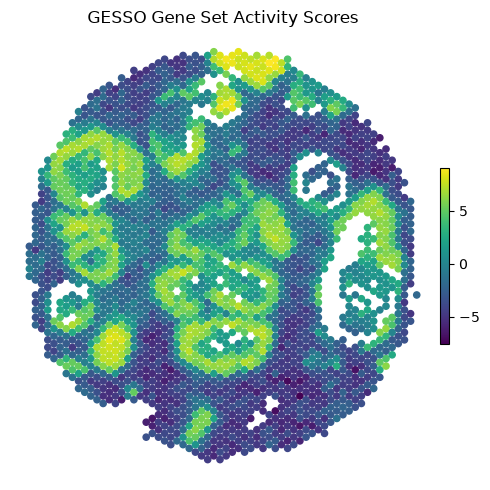

In [6]:
model = GESSO(
    expression_df=expression_df,
    locations_df=locations_df,
    genesets_df=genesets_df,
    k=6,
    normalize_counts_method="normalize-log1p",
)
# compute activity scores for all gene sets in genesets_df
gas_report = model.compute_gas(
    beta=0.33,  # increase beta to increase spatial smoothing strength; must be between 0 and 1
    compute_method="cpu",  # either "cpu" or "lowres"
)
# quickly plot spatial map of activity scores for a specific gene set
figure = gas_report.plot_gas_spatial_map(
    geneset="KEGG_PATHWAYS_IN_CANCER",  # specify the gene set of interest
    size=20,  # dot size
    cmap="viridis",
    figsize=(5, 5),
)  # returns a matplotlib Figure object
display(figure)

You can easily retrieve relevant data in `pd.DataFrame` form from the GESSO gene set activity scores report.

In [7]:
display(gas_report.gas_df())
display(gas_report.gene_contributions_df(geneset="KEGG_PATHWAYS_IN_CANCER"))

,KEGG_PATHWAYS_IN_CANCER,WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT
barcode,,
GTAGACAACCGATGAA-1,-1.137452,0.044172
ACAGATTAGGTTAGTG-1,-0.076933,-1.285475
TGGTATCGGTCTGTAT-1,-1.564224,-1.565298
ATTATCTCGACAGATC-1,-1.624066,-0.296113
TGAGATCAAATACTCA-1,-2.743630,-0.461900
...,...,...
GCCCTGAGGATGGGCT-1,-3.237531,1.022693
CGGGCGATGGATCACG-1,-2.021051,-1.913347
TGCGGACTTGACTCCG-1,-4.610999,0.047913


,KEGG_PATHWAYS_IN_CANCER
ERBB2,0.209451
RARA,0.174657
PRKCA,0.174332
CDH1,0.168812
VEGFA,0.157994
...,...
GSTP1,-0.127424
PDGFRB,-0.139686
CSF1R,-0.144355
FOS,-0.167397


You can also work directly with gene sets in dictionary form.

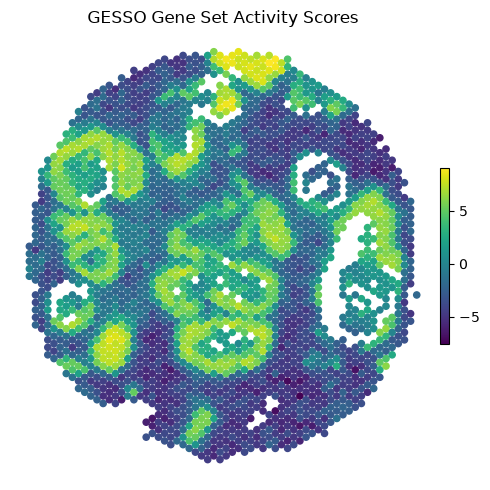

In [8]:
model_alt = GESSO(
    expression_df=expression_df,
    locations_df=locations_df,
    k=6,
    normalize_counts_method="normalize-log1p",
    verbose=False,  # per-call override: suppress all messages from this model
    # (for finer control, use gesso.logging - see above)
)
gas_report = model_alt.compute_gas(
    genesets_dict=genesets_dict, beta=0.33, compute_method="cpu"
)
gas_report.plot_gas_spatial_map(
    geneset="KEGG_PATHWAYS_IN_CANCER", size=20, cmap="viridis", figsize=(5, 5)
)

### Use GESSO to systematically identify spots with significantly elevated gene set activity
Please note that the output of the permutation-based hypothesis test varies with the total number of genes in the dataset. The example dataset used in this demo contains a subset of all genes from the original dataset.

In [9]:
model = GESSO(
    expression_df=expression_df,
    locations_df=locations_df,
    genesets_df=genesets_df,
    k=6,
    normalize_counts_method="normalize-log1p",
    verbose=False,
)
htest_report = model.htest_elevated_gas(
    geneset="KEGG_PATHWAYS_IN_CANCER",
    beta=0.33,
    n_permutations=100,  # number of random gene sets to sample for the test
    n_jobs=4,  # set number of CPUs
)

,x,y,gas,p
barcode,,,,
GTAGACAACCGATGAA-1,7,55,-1.137452,0.97
ACAGATTAGGTTAGTG-1,7,57,-0.076933,0.32
TGGTATCGGTCTGTAT-1,7,59,-1.564224,1.00
ATTATCTCGACAGATC-1,7,61,-1.624066,1.00
TGAGATCAAATACTCA-1,7,63,-2.743630,1.00
...,...,...,...,...
GCCCTGAGGATGGGCT-1,68,74,-3.237531,0.96
CGGGCGATGGATCACG-1,69,75,-2.021051,0.98
TGCGGACTTGACTCCG-1,68,76,-4.610999,0.98


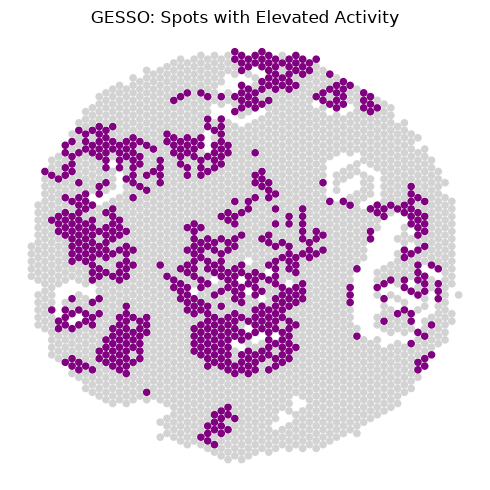

In [10]:
display(htest_report.htest_df())
htest_report.plot_pval_spatial_map(size=20, significance_threshold=0.05)